# 11 Transformers多任务调用、Auto模型与中文分类数据准备

本篇对应 `03-视频/day11`，已核对当天 **12个视频文件名**，并阅读 `01-课件/10-迁移学习-中.pdf` 第35—62页与 `11-迁移学习-下.pdf` 第1—11页。下篇第12—17页仅用于确认完整分类网络与训练的后续边界。本篇主线为：**问答、摘要、NER的Pipeline → 六种Auto模型 → 具体BERT调用 → 中文分类数据加载与预处理**。

第10篇已整理分类、特征提取、遮蔽填空的Pipeline。本篇接着学习另外三个任务，并通过手动前向与后处理理解Pipeline封装了什么。中文分类案例只准备到可交给模型的批次，完整微调留到第12篇。

延续全Markdown Notebook：Python代码按顺序复制到同一个会话运行，实测输出附在代码后；标题、表格、公式与图可直接阅读。所有图都嵌入本Notebook的attachments，不依赖外部图片文件。

**来源与实验边界**：已阅读课件并核对目录，没有逐节转录视频，也没有读取原课程代码与评论CSV。本篇是独立教学实现。使用随机初始化的本地小BERT/BART验证接口与shape，模型没有预训练语义能力；人工构造的答案与BIO标签只验证后处理规则。公开预训练模型代码单独标注“未执行”，不把随机预测解释为真实任务效果。

## 1. 六个任务：输入相近，任务头与输出不同

约定 `B` 为批次样本数，`L` 为padding后的token长度，`D` 为隐藏维度，`C` 为标签数，`V` 为词表大小。输入通常包含 `input_ids`、`attention_mask`；BERT句对还可能有 `token_type_ids`。不同架构接受的键不同。

| 任务 | Auto类 | 主要输出 | 后处理 |
| --- | --- | --- | --- |
| 文本分类 | `AutoModelForSequenceClassification` | logits `(B,C)` | 单标签：类别维softmax；再选标签 |
| 特征提取 | `AutoModel` | hidden states `(B,L,D)` | 按用途取token表示、CLS或池化 |
| 遮蔽填空 | `AutoModelForMaskedLM` | logits `(B,L,V)` | 找mask位置，再在词表维选候选 |
| 抽取式问答 | `AutoModelForQuestionAnswering` | start/end logits，各为 `(B,L)` | 限制在context内，选合法连续片段 |
| 文本摘要 | `AutoModelForSeq2SeqLM` | 前向logits `(B,L_dec,V)`；生成token IDs | `generate`，再decode |
| NER | `AutoModelForTokenClassification` | logits `(B,L,C)` | 每token标签，结合BIO和原文offset合并 |

问答和NER需要“预测位置→原文字符”的对齐；摘要生成新序列。`AutoModel`通常只有基础编码器，不会自动给出情感标签或实体类别。加载模型时必须同时确认架构、任务头、训练任务、语言和tokenizer。

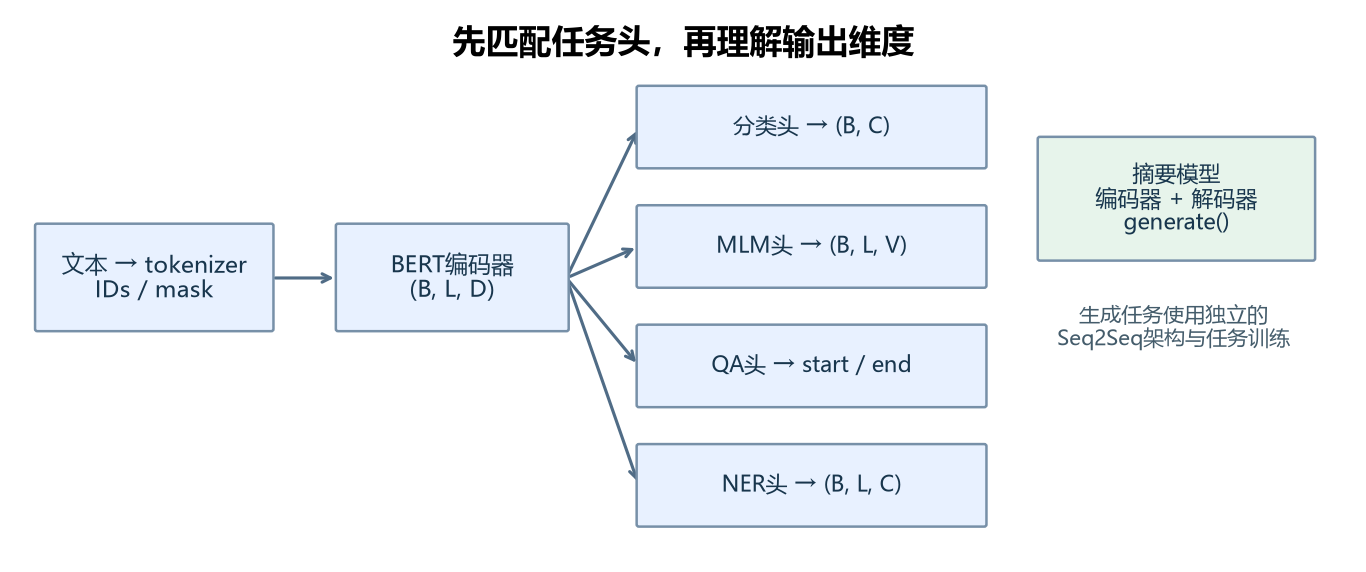

## 2. 环境与可复现约定

课件使用较早的Transformers接口。本篇实测为Python3.12、Transformers4.57.6、Datasets4.4.2、NumPy1.26.4与CPU PyTorch；完整版本见输出。建议在独立环境使用这些版本，不用替换已有项目环境。Datasets是数据处理库，Transformers负责tokenizer和模型。

```text
# 按需在独立环境安装；此行是安装命令，不是Python代码
pip install numpy==1.26.4 transformers==4.57.6 datasets==4.4.2 huggingface-hub==0.36.2 pyarrow==21.0.0 torch matplotlib
```

```python
import csv, json, random, platform
from pathlib import Path
from collections import Counter
import numpy as np
import torch, transformers, datasets
import matplotlib.pyplot as plt
from transformers import (
    BertConfig, BartConfig, BertTokenizerFast, BertForMaskedLM,
    AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
    AutoModelForMaskedLM, AutoModelForQuestionAnswering,
    AutoModelForSeq2SeqLM, AutoModelForTokenClassification,
    DataCollatorWithPadding, pipeline,
)
from datasets import load_dataset
from torch.utils.data import DataLoader

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
transformers.logging.set_verbosity_error()
datasets.disable_progress_bars()
plt.rcParams['font.family'] = 'Microsoft YaHei'
plt.rcParams['axes.unicode_minus'] = False
WORK = Path('nlp_day11_demo')
WORK.mkdir(exist_ok=True)
print('Python:', platform.python_version())
print('NumPy:', np.__version__, '| PyTorch:', torch.__version__)
print('Transformers:', transformers.__version__, '| Datasets:', datasets.__version__)
print('设备: CPU | 固定种子:', SEED)
```

本段实测输出：

```text
Python: 3.12.13
NumPy: 1.26.4 | PyTorch: 2.14.1+cpu
Transformers: 4.57.6 | Datasets: 4.4.2
设备: CPU | 固定种子: 2026
```

代码会在当前目录的 `nlp_day11_demo` 中生成教学词表、CSV与小模型。它们是动手实验文件，不是Notebook阅读时的图片依赖。固定种子可稳定本机演示；跨版本或平台的浮点值与随机输出可能略有差异。

## 3. 建立本地小模型：验证调用，不提供语义能力

为避免把网络下载成功与否混进基础练习，先建立有限中文字符词表和六种小模型，保存后再用Auto接口重新加载。BERT仅1层、隐藏维度32、4个注意力头、最大位置数64；BART也是1层编码器与1层解码器。

同一个tokenizer可在此人工实验中用于BERT与小BART，因为词表和特殊ID由我们明确配置。**真实BART应使用其checkpoint配套tokenizer**，不能把中文BERT tokenizer随意套在公开英文BART上。下方六个任务目录里的权重都随机初始化、没有训练。

```python
DEMO_REVIEWS = {
    'train': [
        (1, '这部电影很好看。'), (0, '剧情太差了。'),
        (1, '演员表演自然。'), (0, '故事无聊。'),
        (1, '画面漂亮，音乐也好听。'), (0, '节奏拖沓，令人失望。'),
        (1, '我说："真好看",值得推荐。'), (0, '看完没有感动。'),
        (1, '这部电影剧情精彩，演员表演自然。' * 10),
    ],
    'validation': [(1, '情节有趣。'), (0, '台词生硬。'), (1, '结尾很温暖。')],
    'test': [(0, '特效粗糙。'), (1, '人物刻画细腻。'), (0, '不值得花时间。')],
}
CONTEXT = '张三在北京学习自然语言处理。李四在上海工作。'
QUESTION = '谁在北京学习？'
ARTICLE = '自然语言处理可以分析文本。模型需要合适的数据。' * 3
extra_texts = [CONTEXT, QUESTION, ARTICLE, '你是谁', '人生该如何起头',
               '张三在北京学习。', '张三在[MASK]学习。', '今天张三在[MASK]学习。']
all_text = ''.join(extra_texts + [t for rows in DEMO_REVIEWS.values() for _,t in rows])
vocab = ['[PAD]', '[UNK]', '[CLS]', '[SEP]', '[MASK]'] + sorted(set(all_text))
vocab_path = WORK/'vocab.txt'
vocab_path.write_text('\n'.join(vocab), encoding='utf-8')
tokenizer = BertTokenizerFast(vocab_file=str(vocab_path), model_max_length=64)
NER_LABELS = {0:'O', 1:'B-PER', 2:'I-PER', 3:'B-LOC', 4:'I-LOC'}

def small_bert(**extra):
    return BertConfig(vocab_size=len(tokenizer), hidden_size=32,
        num_hidden_layers=1, num_attention_heads=4, intermediate_size=64,
        max_position_embeddings=64, pad_token_id=tokenizer.pad_token_id, **extra)

fixtures = {
    'encoder': AutoModel.from_config(small_bert()),
    'classifier': AutoModelForSequenceClassification.from_config(small_bert(
        num_labels=2, id2label={0:'负面',1:'正面'}, label2id={'负面':0,'正面':1})),
    'mlm': AutoModelForMaskedLM.from_config(small_bert()),
    'qa': AutoModelForQuestionAnswering.from_config(small_bert(num_labels=2)),
    'ner': AutoModelForTokenClassification.from_config(small_bert(
        num_labels=5, id2label=NER_LABELS, label2id={v:k for k,v in NER_LABELS.items()})),
}
bart_config = BartConfig(vocab_size=len(tokenizer), d_model=32,
    encoder_layers=1, decoder_layers=1,
    encoder_attention_heads=4, decoder_attention_heads=4,
    encoder_ffn_dim=64, decoder_ffn_dim=64, max_position_embeddings=64,
    pad_token_id=tokenizer.pad_token_id, bos_token_id=tokenizer.cls_token_id,
    eos_token_id=tokenizer.sep_token_id, decoder_start_token_id=tokenizer.cls_token_id,
    forced_eos_token_id=tokenizer.sep_token_id)
fixtures['seq2seq'] = AutoModelForSeq2SeqLM.from_config(bart_config)
for name, model in fixtures.items():
    model.eval()
    model.save_pretrained(WORK/name)
    tokenizer.save_pretrained(WORK/name)
    print(name, '→', type(model).__name__)
print('词表大小:', len(tokenizer), '| 位置上限:', 64)
```

本段实测输出：

```text
encoder → BertModel
classifier → BertForSequenceClassification
mlm → BertForMaskedLM
qa → BertForQuestionAnswering
ner → BertForTokenClassification
seq2seq → BartForConditionalGeneration
词表大小: 131 | 位置上限: 64
```

这些目录分别保存config、tokenizer文件和权重。`from_config`只根据配置构造结构并初始化；`from_pretrained`读取已保存权重。名称含“pretrained”不会让随机权重获得语义能力，能力取决于权重如何训练而来。

## 4. tokenizer输入：批次不等于句对

`tokenizer(['句子A','句子B'])`是两条独立样本，`B=2`；`tokenizer('句子A','句子B')`是一条句对，`B=1`，通常形成 `[CLS] A [SEP] B [SEP]`。课件特征提取用 `encode_plus(text=['你是谁','人生该如何起头'])`，在BERT tokenizer中两元素列表可被解释成句对，不能据此理解成批次。本篇用明确的两种调用消除歧义。

| 输入键 | 含义 | 常见误解 |
| --- | --- | --- |
| `input_ids` | token在词表中的整数ID | ID大小不表示语义强弱 |
| `attention_mask` | 本例1为有效token、0为PAD | 1不等于真实内容字符，CLS/SEP也通常是1 |
| `token_type_ids` | BERT的句段ID，常见0/1 | 它不是位置编号，也不是实体标签 |
| `offset_mapping` | token对应原文的字符起止，end排他 | 句对的两段offset分别相对各自原文 |

```python
tokenizer = AutoTokenizer.from_pretrained(WORK/'encoder', local_files_only=True)
single = tokenizer('你是谁', return_tensors='pt')
batch_inputs = tokenizer(['你是谁', '人生该如何起头'], padding=True, return_tensors='pt')
pair_inputs = tokenizer('你是谁', '人生该如何起头', return_tensors='pt')
fixed_inputs = tokenizer(['你是谁', '人生该如何起头'],
    padding='max_length', truncation=True, max_length=16, return_tensors='pt')
assert batch_inputs.input_ids.shape[0] == 2 and pair_inputs.input_ids.shape[0] == 1
print('单句 / 批次 / 句对:', tuple(single.input_ids.shape),
      tuple(batch_inputs.input_ids.shape), tuple(pair_inputs.input_ids.shape))
print('句对tokens:', tokenizer.convert_ids_to_tokens(pair_inputs.input_ids[0].tolist()))
print('句对type_ids:', pair_inputs.token_type_ids[0].tolist())
print('动态padding:', tuple(batch_inputs.input_ids.shape),
      '| 固定padding:', tuple(fixed_inputs.input_ids.shape))
print('批次attention_mask:', batch_inputs.attention_mask.tolist())
```

本段实测输出：

```text
单句 / 批次 / 句对: (1, 5) (2, 9) (1, 13)
句对tokens: ['[CLS]', '你', '是', '谁', '[SEP]', '人', '生', '该', '如', '何', '起', '头', '[SEP]']
句对type_ids: [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1]
动态padding: (2, 9) | 固定padding: (2, 16)
批次attention_mask: [[1, 1, 1, 1, 1, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1, 1, 1, 1]]
```

`padding=True`把当前批次补到其中最长样本，`padding='max_length'`补到明确上限；`truncation=True`负责截断。只设padding不会自动截断超长文本。批量句对用 `tokenizer(list_A, list_B, ...)`，两个列表长度相同。

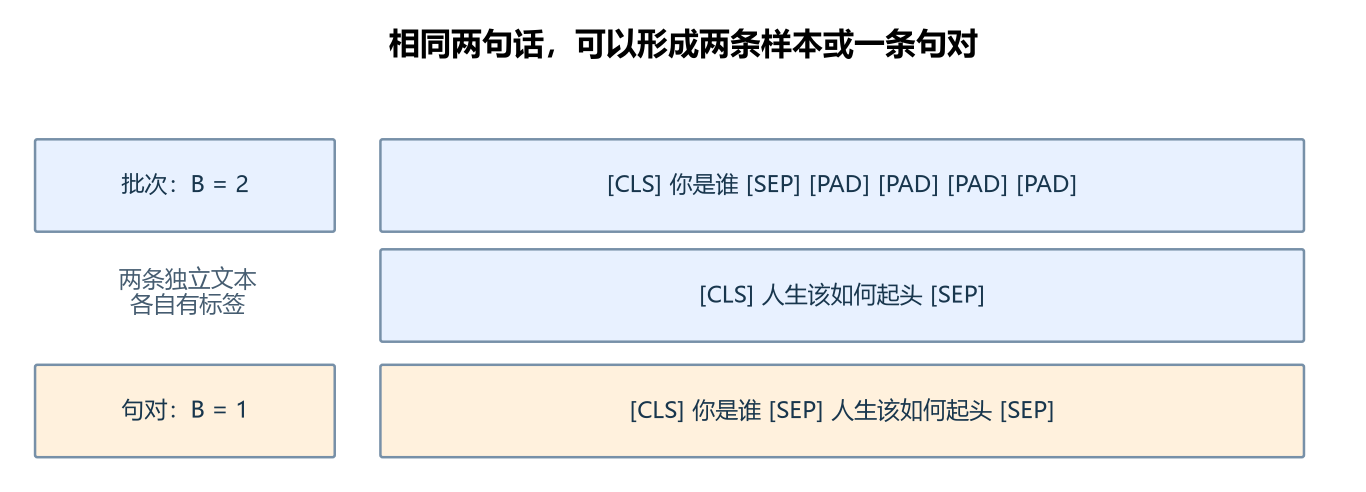

## 5. 手动前向的共同骨架：字典展开、eval与输出对象

`tokenizer(..., return_tensors='pt')`给出类似字典的BatchEncoding。模型需要将键作为参数传入：`model(**inputs)`，其中`**`展开键值。`model(inputs)`会把整个字典放在第一个位置参数中，通常报错。`return_tensors='pt'`让单句的input IDs也有 `(1,L)` 的batch维度；不指定时通常返回Python列表。

`eval()`关闭Dropout等训练行为；`torch.inference_mode()`关闭梯度记录及相关开销；两者作用不同。`eval()`不会自动关闭梯度，也不表示参数被冻结。本篇所有模型在CPU运行，迁移到GPU时模型和张量必须在同一个device。

```python
classifier = AutoModelForSequenceClassification.from_pretrained(
    WORK/'classifier', local_files_only=True).eval()
with torch.inference_mode():
    cls_output = classifier(**batch_inputs)
    cls_probs = cls_output.logits.softmax(dim=-1)
    cls_tuple = classifier(**batch_inputs, return_dict=False)
assert torch.allclose(cls_probs.sum(-1), torch.ones(2))
assert torch.allclose(cls_output.logits, cls_tuple[0])
print('类型:', type(cls_output).__name__)
print('logits:', tuple(cls_output.logits.shape), '| probabilities:', tuple(cls_probs.shape))
print('每行概率和:', cls_probs.sum(-1).tolist())
print('随机预测标签:', [classifier.config.id2label[i] for i in cls_probs.argmax(-1).tolist()])
```

本段实测输出：

```text
类型: SequenceClassifierOutput
logits: (2, 2) | probabilities: (2, 2)
每行概率和: [1.0, 1.0]
随机预测标签: ['正面', '正面']
```

`logits`是未归一化分数，本例两类单标签任务沿类别维softmax。多标签任务通常逐类sigmoid，不能机械沿用softmax。`return_dict=False`改为元组，不同任务、是否提供labels会改变元组内容与位置，阅读代码时优先用 `.logits`、`.last_hidden_state` 等具名字段。这里的标签只是随机分类头的输出，不能用于判断评论。

## 6. Pipeline：抽取式阅读理解

问答Pipeline把问题和上下文一起编码，用问答任务头给每个token起点与终点打分，再恢复原文中的连续答案。输入 `question` 与 `context`；输出 `answer`、`start`、`end`、`score`。`start/end`通常是context中的字符下标，`end`不包含在答案中。

```python
qa_model = AutoModelForQuestionAnswering.from_pretrained(WORK/'qa', local_files_only=True).eval()
qa_pipe = pipeline('question-answering', model=qa_model, tokenizer=tokenizer, device=-1)
qa_result = qa_pipe(question=QUESTION, context=CONTEXT,
    max_seq_len=64, doc_stride=8, max_answer_len=6)
assert qa_result['answer'] == CONTEXT[qa_result['start']:qa_result['end']]
print('问题:', QUESTION)
print('随机问答结果:', qa_result)
print('字符切片核对:', CONTEXT[qa_result['start']:qa_result['end']])
```

本段实测输出：

```text
问题: 谁在北京学习？
随机问答结果: {'score': 0.0025306609459221363, 'start': 17, 'end': 21, 'answer': '上海工作'}
字符切片核对: 上海工作
```

模型随机，答案不必是“张三”。上面的断言只验证offset能恢复同一字符串，不验证回答是否正确。score是模型内部的span评分，不是“答案一定正确”的概率保证。长context还需分窗与跨窗选择，不能仅靠提高字符数或直接删掉标点解决。

## 7. Pipeline：文本摘要

摘要是生成任务。输入文章，模型逐步生成摘要token。课件举例 `sshleifer/distilbart-cnn-12-6`，主要面向英文新闻摘要；不能看到能处理字符串就认为适合中文。中文应选择经过中文摘要训练的checkpoint并验证领域效果。

```python
seq2seq_model = AutoModelForSeq2SeqLM.from_pretrained(WORK/'seq2seq', local_files_only=True).eval()
summary_pipe = pipeline('summarization', model=seq2seq_model, tokenizer=tokenizer, device=-1)
blocked_special_ids = [[i] for i in tokenizer.all_special_ids
                       if i != tokenizer.sep_token_id]
summary_result = summary_pipe(ARTICLE, truncation=True,
    min_new_tokens=2, max_new_tokens=8, do_sample=False, num_beams=1,
    bad_words_ids=blocked_special_ids)
print('随机摘要Pipeline输出:', summary_result)
```

本段实测输出：

```text
随机摘要Pipeline输出: [{'summary_text': '音 音 音 音 音 音 音'}]
```

这里屏蔽部分特殊token以便观察普通token生成，得到的重复字符或无意义片段不代表模型会摘要。`max_new_tokens`控制新增输出长度；tokenizer的`max_length`控制输入编码长度，两个预算不同。贪心生成 `num_beams=1`；增大beam可能增加计算量，不能保证事实准确。生成模型可能编造、遗漏或改变原文事实，应结合人工抽查与任务指标评价。

## 8. Pipeline：命名实体识别（NER）

NER是token分类，常见BIO约定为 `B-X` 实体开头、`I-X` 同类型实体的后续token、`O` 非实体。实体类别来自checkpoint的 `config.id2label`。本篇人工小模型只有PER/LOC，与课件CLUENER checkpoint的完整类别体系不同。

```python
ner_model = AutoModelForTokenClassification.from_pretrained(WORK/'ner', local_files_only=True).eval()
ner_pipe = pipeline('token-classification', model=ner_model, tokenizer=tokenizer,
                    aggregation_strategy='simple', device=-1)
ner_result = ner_pipe(CONTEXT)
print('随机实体组数量:', len(ner_result))
print('前3组:', ner_result[:3])
for item in ner_result:
    assert 0 <= item['start'] < item['end'] <= len(CONTEXT)
```

本段实测输出：

```text
随机实体组数量: 11
前3组: [{'entity_group': 'PER', 'score': 0.235462, 'word': '张 三 在 北 京 学', 'start': 0, 'end': 6}, {'entity_group': 'LOC', 'score': 0.22343823, 'word': '习', 'start': 6, 'end': 7}, {'entity_group': 'PER', 'score': 0.26600975, 'word': '自', 'start': 7, 'end': 8}]
```

`aggregation_strategy='none'`偏向逐token输出，`simple`尝试合并连续BIO标签。分词出现子词时，first/average/max策略各有适用条件，需要fast tokenizer及正确的词对齐。`word`字段可能包含分词痕迹或中文空格，展示实体原文时优先用 `text[start:end]`。

Pipeline不会通过合并修正模型全部错误；随机BIO输出更不能作为标注结果。第16节用人工标签把合并规则独立讲清。

## 9. 公开预训练模型：可选使用模板（未执行）

以下完整模型ID来自课件。代码会下载模型，网络、权限、磁盘、框架版本和模型文件均可能影响加载。本篇没有运行这些checkpoint，因此不提供真实效果或预测输出。

```python
# 可选模板：未执行，需要网络与对应模型资源
real_qa = pipeline('question-answering',
    model='luhua/chinese_pretrain_mrc_roberta_wwm_ext_large', device=-1)
print(real_qa(question=QUESTION, context=CONTEXT))

real_summary = pipeline('summarization', model='sshleifer/distilbart-cnn-12-6', device=-1)
english_article = ('Natural language processing helps computers analyze text. '
                   'Researchers train models with carefully prepared datasets. ' * 5)
print(real_summary(english_article, max_new_tokens=40, do_sample=False))

real_ner = pipeline('token-classification',
    model='uer/roberta-base-finetuned-cluener2020-chinese',
    aggregation_strategy='simple', device=-1)
print(real_ner(CONTEXT))
```

实际项目应记录checkpoint版本、数据领域、输入长度、标签定义与验证结果。基础中文BERT，例如 `google-bert/bert-base-chinese`，可提供预训练编码器与MLM能力；新增分类或NER头往往还需任务训练，不能把初始化警告忽略后当成成熟分类器。

## 10. Auto是什么：根据config挑实际模型类

`AutoTokenizer`与`AutoModelFor...`提供统一入口，根据本地或远程checkpoint配置选择实际类。它们不会自动决定业务标签、补齐训练数据或把任务头转换成另一个已训练任务。`AutoModelForMaskedLM`加载BERT目录后，实际对象可能是 `BertForMaskedLM`；换成其他支持的架构，才会选择另一实现。

```python
encoder = AutoModel.from_pretrained(WORK/'encoder', local_files_only=True).eval()
mlm_model = AutoModelForMaskedLM.from_pretrained(WORK/'mlm', local_files_only=True).eval()
print('tokenizer实际类:', type(tokenizer).__name__)
print('AutoModel实际类:', type(encoder).__name__)
print('AutoModelForMaskedLM实际类:', type(mlm_model).__name__)
print('model_type:', encoder.config.model_type)
print('分类id2label:', classifier.config.id2label)
```

本段实测输出：

```text
tokenizer实际类: BertTokenizerFast
AutoModel实际类: BertModel
AutoModelForMaskedLM实际类: BertForMaskedLM
model_type: bert
分类id2label: {0: '负面', 1: '正面'}
```

Auto接口适合切换同类任务的架构；具体类适合已确定架构或需要访问实现细节的场合。两种写法若加载同一checkpoint、相同模式与输入，计算结果应一致。基础编码器目录拿去构造分类模型可能出现随机新头；任务名称相似也不意味着权重可无损互换。

## 11. Auto特征提取：token表示、CLS与池化

`last_hidden_state`给最后一层每个token的表示 `(B,L,D)`，包含CLS、SEP与PAD位置。普通BERT的 `pooler_output`是首token经过线性层与tanh：

$$p=\tanh(W h_{[CLS]}+b)$$

它**不是所有token的平均值**。课件第44—45页对pooler的平均池化描述需要修正。某些架构没有pooler字段；不能把这一结构推广到全部AutoModel。

均值池化是另一个显式选择：给内容token权重1，PAD和特殊token权重0，求加权平均。即使得到 `(B,D)`，也不代表经过句向量相似度训练，不保证语义检索质量。

```python
feature_inputs = tokenizer(['你是谁', '人生该如何起头'], padding=True,
    return_special_tokens_mask=True, return_tensors='pt')
special = feature_inputs.pop('special_tokens_mask')
with torch.inference_mode():
    features = encoder(**feature_inputs)
    expected_pooler = torch.tanh(encoder.pooler.dense(features.last_hidden_state[:,0]))
    content_mask = (feature_inputs.attention_mask.bool() & ~special.bool()).unsqueeze(-1)
    counts = content_mask.sum(dim=1)
    if torch.any(counts == 0):
        raise ValueError('至少一条样本没有内容token，不能求内容均值')
    mean_features = (features.last_hidden_state * content_mask).sum(1) / counts
assert torch.allclose(features.pooler_output, expected_pooler, atol=1e-6)
print('token特征:', tuple(features.last_hidden_state.shape))
print('pooler / 内容均值:', tuple(features.pooler_output.shape), tuple(mean_features.shape))
print('内容token数:', counts.squeeze(-1).tolist())
print('pooler与均值相同吗:', torch.allclose(features.pooler_output, mean_features))
```

本段实测输出：

```text
token特征: (2, 9, 32)
pooler / 内容均值: (2, 32) (2, 32)
内容token数: [3, 7]
pooler与均值相同吗: False
```

模型的attention mask解决注意力读取问题，池化时仍应单独排除不需要的token。保留PAD向量直接平均，会让同一句话的特征随padding长度变化。

## 12. Auto遮蔽填空：动态定位mask

MLM输出 `(B,L,V)`，每个位置都有一组词表分数。先查找 `input_ids == mask_token_id`，再选择这些位置的logits，而不是硬编码第6个位置。句首增加文字、分词器变化或句子变长，都可能移动mask。

```python
masked_texts = ['张三在[MASK]学习。', '今天张三在[MASK]学习。']
masked_inputs = tokenizer(masked_texts, padding=True, return_tensors='pt')
mask_positions = (masked_inputs.input_ids == tokenizer.mask_token_id).nonzero(as_tuple=False)
assert len(mask_positions) == 2
with torch.inference_mode():
    mlm_logits = mlm_model(**masked_inputs).logits
print('MLM logits:', tuple(mlm_logits.shape))
print('mask的(batch, position):', mask_positions.tolist())
for b, pos in mask_positions.tolist():
    probabilities = mlm_logits[b,pos].softmax(dim=-1)
    top_p, top_ids = probabilities.topk(3)
    print('样本', b, '| 随机候选:', list(zip(
        tokenizer.convert_ids_to_tokens(top_ids.tolist()),
        [round(v,4) for v in top_p.tolist()])))
```

本段实测输出：

```text
MLM logits: (2, 11, 131)
mask的(batch, position): [[0, 4], [1, 6]]
样本 0 | 随机候选: [('S', 0.0106), ('差', 0.0102), ('失', 0.0099)]
样本 1 | 随机候选: [('差', 0.0098), ('S', 0.0097), ('值', 0.0092)]
```

一个mask预测一个token，中文一个词可能由多个token组成。多个mask的逐位置候选不等于对整个句子的联合最优补全。这里的top-3来自随机模型；真实预测也可能包含特殊token，是否过滤应由任务规则明确决定。MLM不能直接替代逐token自回归续写的聊天模型。

## 13. Auto问答：只在context内选合法答案

手动问答时，tokenizer输入为 `(question, context)`。fast tokenizer的 `sequence_ids(0)`在本例用0表示问题、1表示context、None表示特殊token。`offset_mapping`在context token上直接指向context字符；不要把问题中的offset拿来切context。

课件独立对start/end做argmax，可能起点晚于终点、落到问题中或跨度太长。一个简化的合法span解码应限制：两端均在context；`s≤e`；答案token数不超过上限。下面用 `start_logit[s]+end_logit[e]`评分，穷举适合短教学样本，时间复杂度约 `O(L×最大答案长度)`。

```python
qa_encoding = tokenizer(QUESTION, CONTEXT, return_offsets_mapping=True,
    return_tensors='pt', truncation='only_second', max_length=64)
qa_offsets = qa_encoding.pop('offset_mapping')[0].tolist()
qa_sequence_ids = qa_encoding.sequence_ids(0)

def best_context_span(start_logits, end_logits, sequence_ids, offsets,
                      attention_mask, context, max_answer_tokens=6):
    if max_answer_tokens < 1:
        raise ValueError('最大答案长度至少为1')
    valid = [i for i,sid in enumerate(sequence_ids)
             if sid == 1 and attention_mask[i] == 1 and offsets[i][1] > offsets[i][0]]
    allowed = set(valid)
    candidates = []
    for s in valid:
        for e in range(s, min(len(sequence_ids), s + max_answer_tokens)):
            if any(i not in allowed for i in range(s,e+1)):
                break
            score = float(start_logits[s] + end_logits[e])
            candidates.append((score,s,e))
    if not candidates:
        raise ValueError('编码结果中没有可用的context token')
    score,s,e = max(candidates, key=lambda item:item[0])
    begin,end = offsets[s][0],offsets[e][1]
    return {'answer':context[begin:end], 'start':begin, 'end':end,
            'token_span':(s,e), 'logit_sum':round(score,4)}

with torch.inference_mode():
    qa_output = qa_model(**qa_encoding)
random_span = best_context_span(qa_output.start_logits[0], qa_output.end_logits[0],
    qa_sequence_ids, qa_offsets, qa_encoding.attention_mask[0].tolist(), CONTEXT)
print('start/end shape:', tuple(qa_output.start_logits.shape), tuple(qa_output.end_logits.shape))
print('随机模型的合法span:', random_span)

# 人工logits只验证解码规则，故意让全局最大值落在问题token上
fake_start = torch.full_like(qa_output.start_logits[0], -10.)
fake_end = torch.full_like(qa_output.end_logits[0], -10.)
question_index = next(i for i,sid in enumerate(qa_sequence_ids) if sid == 0)
zhang = next(i for i,sid in enumerate(qa_sequence_ids) if sid == 1 and qa_offsets[i] == [0,1])
san = next(i for i,sid in enumerate(qa_sequence_ids) if sid == 1 and qa_offsets[i] == [1,2])
fake_start[question_index] = 99.
fake_end[question_index] = 99.
fake_start[zhang] = 8.
fake_end[san] = 9.
controlled_span = best_context_span(fake_start, fake_end, qa_sequence_ids, qa_offsets,
    qa_encoding.attention_mask[0].tolist(), CONTEXT)
assert controlled_span['answer'] == '张三'
assert (controlled_span['start'], controlled_span['end']) == (0,2)
print('无约束argmax位置:', int(fake_start.argmax()), int(fake_end.argmax()))
print('人工logits + 合法解码:', controlled_span)
```

本段实测输出：

```text
start/end shape: (1, 32) (1, 32)
随机模型的合法span: {'answer': '上海工作', 'start': 17, 'end': 21, 'token_span': (26, 29), 'logit_sum': 0.3399}
无约束argmax位置: 1 1
人工logits + 合法解码: {'answer': '张三', 'start': 0, 'end': 2, 'token_span': (9, 10), 'logit_sum': 17.0}
```

`logit_sum`是本函数的排序分数，不是概率，也不保证与Pipeline score数值一致。这里演示“上下文有答案”的简化情况；支持无答案的数据集还需比较CLS/null分数并在验证集确定阈值，不能永远强行返回一个片段。

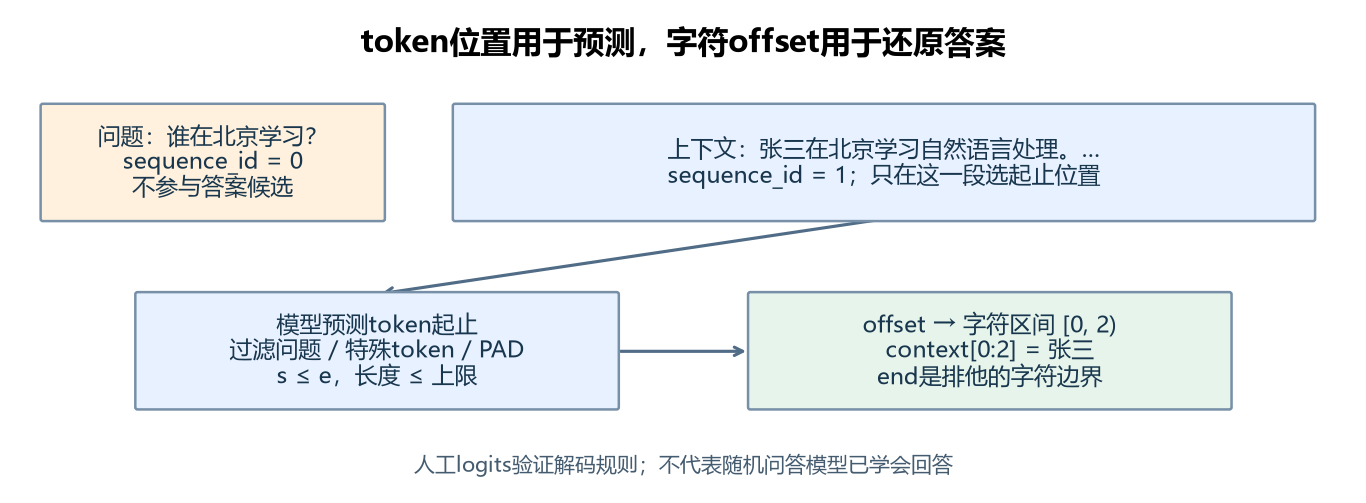

## 14. 长文本问答与原文对齐

BERT长度按token计算，且包含CLS/SEP等特殊token；字符数只是近似。问答的总预算还要减去问题长度。`truncation='only_second'`保留问题、截断context，但如果答案恰好在被截掉的尾部，就无法找回。

长文本通常需要：

1. 编码时对context使用滑动窗口，设置合理`stride`，并返回 `overflow_to_sample_mapping` 与 `offset_mapping`。
2. 每个窗口只在自己的context token中找合法span，映射回原样本与原文字符区间。
3. 对跨窗重叠候选去重，并根据任务解码规则合并评分；支持无答案时同时处理null阈值。
4. 检查问题本身是否超预算、有效context是否为空、最大答案长度是否适合数据。

本篇短问答仅验证单窗解码；没有把它声称为完整长文QA系统。Pipeline通常封装分窗，但仍需显式设置输入长度等参数并核对模型上限。

不要为“让答案看起来更连续”先删除中文标点或空白再返回原文下标。清洗会改变字符坐标，需要额外保留清洗前后的映射；直接在原context上用offset切片更容易检查。

## 15. Auto摘要：前向与generate不是一回事

Seq2Seq前向通常需要解码器输入，输出每个解码位置的词表logits。`generate`负责解码循环，返回完整生成token IDs，再用 `batch_decode(skip_special_tokens=True)`变为字符串。推理时不要把前向logits当成已经生成好的摘要。

本篇BART接受 `input_ids` 与 `attention_mask`，不接受BERT的 `token_type_ids`；明确筛选输入键。公开模型也应根据其实际接口处理，不能把所有tokenizer附加字段都直接传入。

```python
summary_inputs = tokenizer(ARTICLE, truncation=True, max_length=64, return_tensors='pt')
summary_model_inputs = {k:summary_inputs[k] for k in ('input_ids','attention_mask')}
with torch.inference_mode():
    generated_ids = seq2seq_model.generate(**summary_model_inputs,
        min_new_tokens=2, max_new_tokens=8, do_sample=False, num_beams=1,
        bad_words_ids=blocked_special_ids)
decoded_summaries = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)
assert generated_ids.ndim == 2 and generated_ids.shape[0] == 1
assert decoded_summaries[0] == summary_result[0]['summary_text']
print('输入shape:', tuple(summary_inputs.input_ids.shape))
print('生成IDs shape:', tuple(generated_ids.shape))
print('生成IDs:', generated_ids[0].tolist())
print('随机生成文本:', decoded_summaries)
```

本段实测输出：

```text
输入shape: (1, 64)
生成IDs shape: (1, 9)
生成IDs: [2, 127, 127, 127, 127, 127, 127, 127, 3]
随机生成文本: ['音 音 音 音 音 音 音']
```

encoder-decoder返回序列通常含初始解码token，所以返回长度不一定等于`max_new_tokens`。本例在相同输入、配置和eval模式下，与摘要Pipeline文本一致，证明两条调用路径相通；并不证明摘要语义正确。实际批量摘要还要对输入padding、输出截断、事实一致性与耗时做评估。

## 16. Auto NER：从逐token标签还原实体

NER logits为 `(B,L,C)`；沿标签维argmax得到每个token的label ID。先排除special/PAD，再把offset与BIO合并。下面严格规定：`I-X`必须紧接同类实体，且字符区间相邻；孤立或错类型I直接报错，提醒调用者数据或预测序列不满足规则。生产方案也可选择有记录的修复或约束解码，但应明确策略。

```python
ner_text = '张三在北京学习。'
ner_encoding = tokenizer(ner_text, return_offsets_mapping=True,
    return_special_tokens_mask=True, return_tensors='pt')
ner_offsets = ner_encoding.pop('offset_mapping')[0].tolist()
ner_special = ner_encoding.pop('special_tokens_mask')[0].tolist()
with torch.inference_mode():
    ner_logits = ner_model(**ner_encoding).logits
random_tags = [ner_model.config.id2label[i] for i in ner_logits.argmax(-1)[0].tolist()]
print('NER logits:', tuple(ner_logits.shape))
print('随机逐token标签:', list(zip(
    tokenizer.convert_ids_to_tokens(ner_encoding.input_ids[0].tolist()), random_tags)))

def merge_bio(text, tags, offsets, special_mask, attention_mask):
    entities, current = [], None
    def finish():
        nonlocal current
        if current is not None:
            current['text'] = text[current['start']:current['end']]
            entities.append(current)
            current = None
    for tag,(start,end),special,attend in zip(tags,offsets,special_mask,attention_mask):
        if special or not attend or end <= start:
            finish()
            continue
        if tag == 'O':
            finish()
        elif tag.startswith('B-'):
            finish()
            current = {'label':tag[2:], 'start':start, 'end':end}
        elif tag.startswith('I-'):
            if current is None or current['label'] != tag[2:] or current['end'] != start:
                raise ValueError('孤立、错类型或不相邻的I标签: ' + tag)
            current['end'] = end
        else:
            raise ValueError('未知BIO标签: ' + tag)
    finish()
    return entities

# 人工BIO标注，独立验证offset合并；不采用随机模型标签充当正确答案
by_start = {0:'B-PER', 1:'I-PER', 3:'B-LOC', 4:'I-LOC'}
gold_tags = [by_start.get(s,'O') if not special else 'O'
             for (s,e),special in zip(ner_offsets,ner_special)]
entities = merge_bio(ner_text, gold_tags, ner_offsets, ner_special,
                     ner_encoding.attention_mask[0].tolist())
assert [(e['label'],e['text']) for e in entities] == [('PER','张三'),('LOC','北京')]
print('人工标签合并:', entities)
try:
    merge_bio('张', ['I-PER'], [(0,1)], [0], [1])
except ValueError as exc:
    print('异常BIO检查:', str(exc))
else:
    raise AssertionError('孤立I应被本例严格策略拒绝')
```

本段实测输出：

```text
NER logits: (1, 10, 5)
随机逐token标签: [('[CLS]', 'I-PER'), ('张', 'I-PER'), ('三', 'I-PER'), ('在', 'I-PER'), ('北', 'I-PER'), ('京', 'I-PER'), ('学', 'I-PER'), ('习', 'B-LOC'), ('。', 'I-PER'), ('[SEP]', 'I-PER')]
人工标签合并: [{'label': 'PER', 'start': 0, 'end': 2, 'text': '张三'}, {'label': 'LOC', 'start': 3, 'end': 5, 'text': '北京'}]
异常BIO检查: 孤立、错类型或不相邻的I标签: I-PER
```

本函数只处理单条样本，假设每个token及其offset按原文顺序排列，不支持嵌套实体和同一片段的多类型标注。遇英文子词或非连续标注，要使用适合实际数据的word_ids/offset规则；训练时还需决定一个词的多个子词怎样对应labels，不能把分词前的标签数直接当成token数。

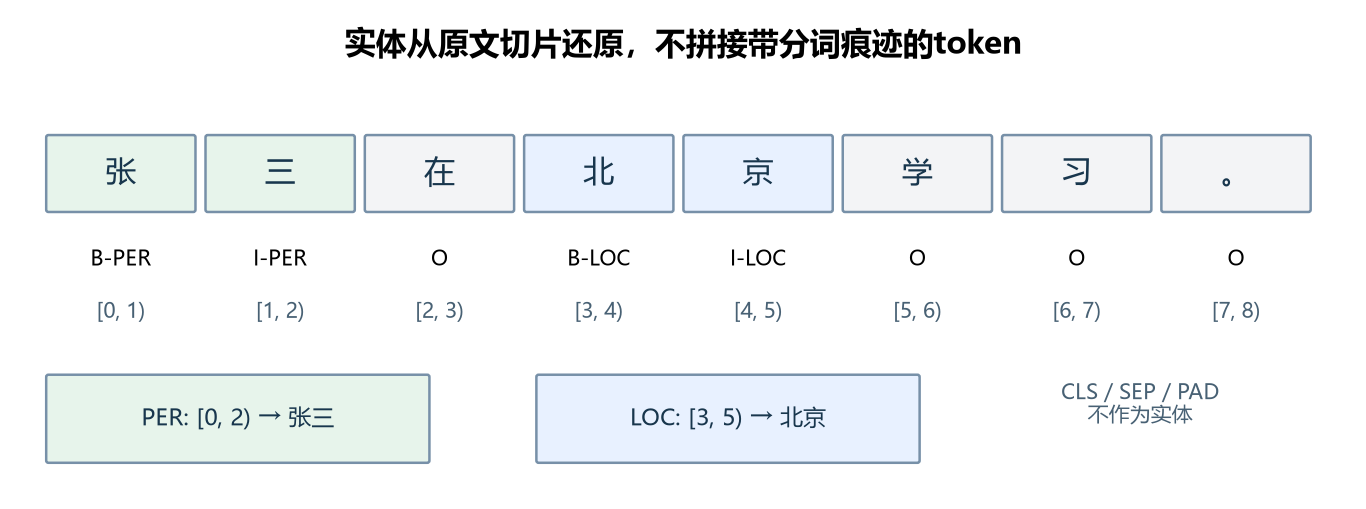

## 17. 具体BERT方式：同一权重，计算应一致

课件用 `BertTokenizer` 与 `BertForMaskedLM`展示具体类。普通BERT tokenizer和fast版本都可做MLM；本篇继续使用 `BertTokenizerFast`，便于问答与NER读offset。Auto并不是“另一种更强的模型”，其作用是选择类。

```python
specific_tokenizer = BertTokenizerFast.from_pretrained(WORK/'mlm', local_files_only=True)
specific_model = BertForMaskedLM.from_pretrained(WORK/'mlm', local_files_only=True).eval()
specific_inputs = specific_tokenizer(masked_texts, padding=True, return_tensors='pt')
with torch.inference_mode():
    specific_logits = specific_model(**specific_inputs).logits
    reloaded_auto_logits = mlm_model(**masked_inputs).logits
max_diff = (specific_logits - reloaded_auto_logits).abs().max().item()
assert torch.equal(specific_inputs.input_ids, masked_inputs.input_ids)
assert torch.allclose(specific_logits, reloaded_auto_logits, atol=1e-6)
print('具体类:', type(specific_model).__name__)
print('Auto / 具体类最大logits差:', max_diff)
```

本段实测输出：

```text
具体类: BertForMaskedLM
Auto / 具体类最大logits差: 0.0
```

一致性成立的前提是同一checkpoint、配套tokenizer、相同输入、相同eval模式与数值设置。若一份模型还在train模式，Dropout可能制造差异；若重新`from_config`构造，则权重本就不是同一份。课件 `model(**inputs)`与`model(inputs)`的区别也适用于具体类。

## 18. 中文分类案例：先把数据边界确定

课件案例为中文评论二分类：`0`负面，`1`正面；CSV字段为 `label,text`。课件展示train9600、validation1200、test1200，这些数量属于原课程数据，本篇没有读取或验证原CSV。

本篇使用第3节定义的人工数据：train9条、validation3条、test3条，仅演示加载、质检与批次准备。第9条训练样本故意很长，用来观察截断；含逗号和引号的评论用来检查CSV解析。这样的小数据不能用于报告业务准确率。

| 划分 | 用途 | 加载建议 |
| --- | --- | --- |
| train | 后续计算loss并更新模型 | 可shuffle；是否drop_last取决于训练需求 |
| validation | 选择超参数、阈值与模型 | 通常不shuffle、不drop_last |
| test | 最终独立评估 | 不用于选择模型；不shuffle、不drop_last |

划分不等于简单按文件名分开。相同评论、同一用户/产品、同源改写可能造成泄漏；实际数据应按业务来源或时间设计划分，再检查重叠。

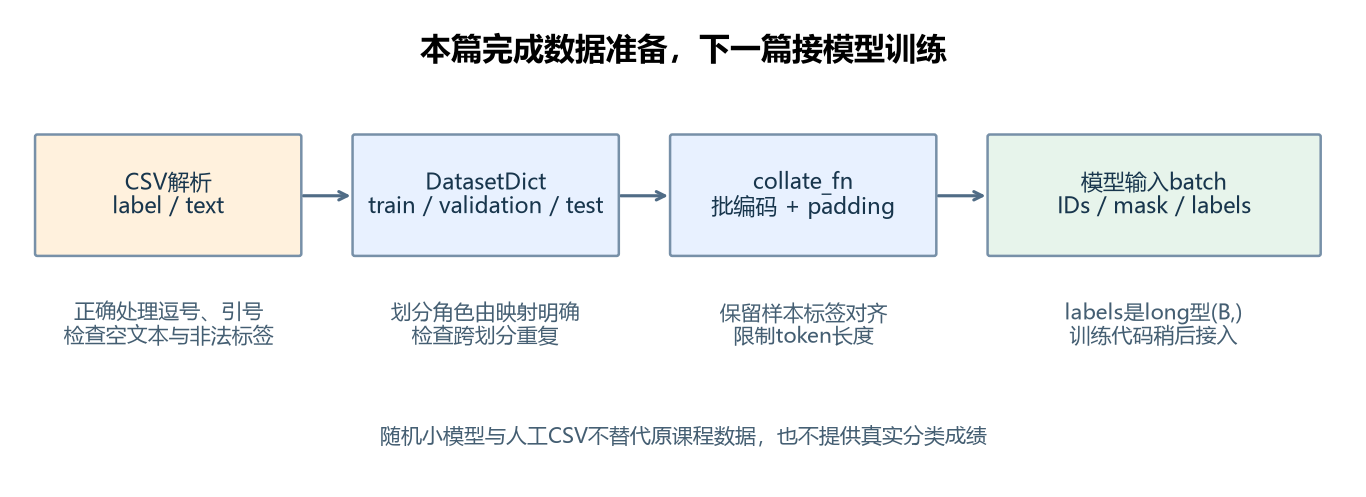

## 19. CSV与Datasets：一次明确加载三个划分

CSV允许字段内含逗号、引号甚至换行，不能用 `line.split(',')`读取。用标准CSV工具写入，用Datasets或pandas解析。下方Dataset每个元素是字典，文本仍保持原样；不在加载时盲目删标点。

```python
data_dir = WORK/'reviews'
data_dir.mkdir(exist_ok=True)
data_files = {}
for split,rows in DEMO_REVIEWS.items():
    path = data_dir/(split+'.csv')
    with path.open('w', encoding='utf-8', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['label','text'])
        writer.writerows(rows)
    data_files[split] = str(path)
review_data = load_dataset('csv', data_files=data_files)
print('类型:', type(review_data).__name__)
print('各划分条数:', {k:len(v) for k,v in review_data.items()})
print('字段类型:', review_data['train'].features)
print('含逗号与引号的原文:', review_data['train'][6]['text'])
assert review_data['train'][6]['text'] == DEMO_REVIEWS['train'][6][1]
```

本段实测输出：

```text
类型: DatasetDict
各划分条数: {'train': 9, 'validation': 3, 'test': 3}
字段类型: {'label': Value('int64'), 'text': Value('string')}
含逗号与引号的原文: 我说："真好看",值得推荐。
```

课件分别 `load_dataset('csv', data_files=某文件, split='train')`：如果只传单个文件，它默认进入名为train的加载split；即使那个文件来自test.csv，返回名叫train也只是这次加载的名字，**不会改变文件原本的业务角色**。用上面的data_files映射更清楚。也可以选择 `review_data['validation']` 单独读取验证划分。

Dataset通常使用Arrow数据结构，支持索引、select和map等处理；DataLoader负责迭代成批，二者职责不同。

## 20. 最小数据质检：标签、空文本与跨划分重复

二分类标签必须在约定范围内，字符串标签需先统一映射为整数。空文本、None、错列名、意外浮点标签等都应在训练前发现。下面保守地按“去掉两端空白的完整字符串”检查精确重复；它不能发现语义相同的改写或所有业务泄漏。

```python
def check_review_data(data):
    text_sets = {}
    report = {}
    for split,ds in data.items():
        if not {'label','text'}.issubset(ds.column_names):
            raise ValueError(split + '缺少label/text列')
        cleaned = []
        for i,row in enumerate(ds):
            if not isinstance(row['text'],str) or not row['text'].strip():
                raise ValueError(f'{split}[{i}]文本为空或非字符串')
            if type(row['label']) is not int or row['label'] not in (0,1):
                raise ValueError(f'{split}[{i}]标签应为整数0/1')
            cleaned.append(row['text'].strip())
        if len(set(cleaned)) != len(cleaned):
            raise ValueError(split + '存在划分内精确重复')
        text_sets[split] = set(cleaned)
        report[split] = {'n':len(ds), 'labels':dict(sorted(Counter(ds['label']).items()))}
    names = list(text_sets)
    for i,a in enumerate(names):
        for b in names[i+1:]:
            if text_sets[a] & text_sets[b]:
                raise ValueError(f'{a}/{b}存在跨划分精确重复')
    return report

quality_report = check_review_data(review_data)
print('数据检查:', quality_report)
leaky_data = datasets.DatasetDict({
    'train': review_data['train'],
    'validation': datasets.Dataset.from_dict({'label':[1], 'text':[DEMO_REVIEWS['train'][0][1]]}),
})
try:
    check_review_data(leaky_data)
except ValueError as exc:
    print('人为泄漏被发现:', str(exc))
else:
    raise AssertionError('构造的重复数据应被拒绝')
```

本段实测输出：

```text
数据检查: {'train': {'n': 9, 'labels': {0: 4, 1: 5}}, 'validation': {'n': 3, 'labels': {0: 1, 1: 2}}, 'test': {'n': 3, 'labels': {0: 2, 1: 1}}}
人为泄漏被发现: train/validation存在跨划分精确重复
```

不要先混合三个划分，再学习标签映射、词表或进行数据依赖的筛选。使用公开预训练tokenizer时不会从这些评论重新拟合词表；如果自己训练tokenizer或统计归一化参数，通常只使用训练集。

## 21. collate_fn与DataLoader：组成模型可用batch

Dataset给出一条条 `{'label':整数, 'text':文本}`；DataLoader先取一个样本列表，再交给collate_fn。collate按列表顺序提取texts与labels，调用tokenizer一次完成批编码、截断和padding。

课件使用 `batch_size=8`、固定 `max_length=500`。500适合与否取决于模型位置上限、数据分布与显存。本篇小BERT位置上限64，选择48作为输入预算，不能直接复制500。

```python
MAX_TOKENS = 48
assert 2 <= MAX_TOKENS <= classifier.config.max_position_embeddings

def collate_reviews(examples):
    texts = [row['text'] for row in examples]
    batch = tokenizer(texts, padding=True, truncation=True,
        max_length=MAX_TOKENS, return_tensors='pt')
    batch['labels'] = torch.tensor([row['label'] for row in examples], dtype=torch.long)
    return batch

train_loader = DataLoader(review_data['train'], batch_size=4, shuffle=True,
    drop_last=False, collate_fn=collate_reviews,
    generator=torch.Generator().manual_seed(SEED), num_workers=0)
validation_loader = DataLoader(review_data['validation'], batch_size=2, shuffle=False,
    drop_last=False, collate_fn=collate_reviews, num_workers=0)
test_loader = DataLoader(review_data['test'], batch_size=2, shuffle=False,
    drop_last=False, collate_fn=collate_reviews, num_workers=0)

first_train_batch = next(iter(train_loader))
print('训练batch各键:', {k:(tuple(v.shape),str(v.dtype)) for k,v in first_train_batch.items()})
print('本批有效token数:', first_train_batch['attention_mask'].sum(1).tolist())
print('验证batch大小:', [b['labels'].shape[0] for b in validation_loader])
print('测试batch大小:', [b['labels'].shape[0] for b in test_loader])
assert sum(b['labels'].numel() for b in test_loader) == len(review_data['test'])
```

本段实测输出：

```text
训练batch各键: {'input_ids': ((4, 48), 'torch.int64'), 'token_type_ids': ((4, 48), 'torch.int64'), 'attention_mask': ((4, 48), 'torch.int64'), 'labels': ((4,), 'torch.int64')}
本批有效token数: [12, 8, 7, 48]
验证batch大小: [2, 1]
测试batch大小: [2, 1]
```

本例batch大小4，最后一批可能只有1条；验证3条按2条一批得到2+1，保留全部样本。训练 `drop_last=True`会丢掉不足一批的数据，有特定需求时才启用；不要因为课件用了它就把测试尾批也丢掉。

Windows独立脚本若使用多个worker，入口应放在 `if __name__ == '__main__':` 下；Notebook初学示例使用 `num_workers=0`减少进程问题。`shuffle`改变样本顺序，正确collate仍必须保持文本与标签对应。

## 22. 另一条预处理路线：Dataset.map + DataCollatorWithPadding

上节在每次迭代时重新tokenize。静态数据也可先 `map`批量编码，保留不等长的ID列表，再在取batch时padding。两种方案都合理，不要在map阶段把每条样本固定补到500，又期望collator恢复动态节省。

```python
def tokenize_review_batch(examples):
    result = tokenizer(examples['text'], truncation=True, max_length=MAX_TOKENS,
                       padding=False)
    result['labels'] = examples['label']
    return result

encoded_reviews = review_data.map(tokenize_review_batch, batched=True,
    remove_columns=['text','label'])
padding_collator = DataCollatorWithPadding(tokenizer=tokenizer, padding=True,
                                         return_tensors='pt')
sample_indices = [0,4,8]
online_batch = collate_reviews([review_data['train'][i] for i in sample_indices])
cached_batch = padding_collator([encoded_reviews['train'][i] for i in sample_indices])
assert set(online_batch) == set(cached_batch)
assert all(torch.equal(online_batch[k],cached_batch[k]) for k in online_batch)
print('map后字段:', encoded_reviews['train'].column_names)
print('三条编码长度:', [len(encoded_reviews['train'][i]['input_ids']) for i in sample_indices])
print('collator后的shape:', {k:tuple(v.shape) for k,v in cached_batch.items()})
print('两条路线结果一致:', True)
```

本段实测输出：

```text
map后字段: ['input_ids', 'token_type_ids', 'attention_mask', 'labels']
三条编码长度: [10, 13, 48]
collator后的shape: {'input_ids': (3, 48), 'token_type_ids': (3, 48), 'attention_mask': (3, 48), 'labels': (3,)}
两条路线结果一致: True
```

`batched=True`表示map函数接收“字段→列表”的批数据，不是单条样本字典。原始text等字符串列要在交给通用padding collator前移除，避免它尝试把文本转成张量。提前编码会占用缓存空间，但可省重复分词；在线collate更灵活，适合每次动态改变文本的场景。

## 23. 长度与padding验收：看截断率和浪费比例

输入上限应按实际token长度分布选择，包含特殊token。自注意力计算通常随序列长度近似平方增长；固定补到很长的长度会增加计算。动态padding节约程度取决于当前batch最长样本，短长样本混在一起仍可能有大量PAD。

```python
raw_lengths = np.array([len(tokenizer(text, truncation=False)['input_ids'])
                       for text in review_data['train']['text']])
truncated_n = int((raw_lengths > MAX_TOKENS).sum())
inspection_indices = [0,1,4,6]
inspection_batch = collate_reviews([review_data['train'][i] for i in inspection_indices])
attention = inspection_batch['attention_mask']
dynamic_pad_fraction = 1. - attention.sum().item() / attention.numel()
fixed_pad_fraction = 1. - attention.sum().item() / (len(inspection_indices) * MAX_TOKENS)
print('训练集原token长度:', raw_lengths.tolist())
print('长度分位数p50/p90/p100:', np.percentile(raw_lengths,[50,90,100]).round(1).tolist())
print(f'超过{MAX_TOKENS}的样本: {truncated_n}/{len(raw_lengths)}')
print('短文本检查batch shape:', tuple(attention.shape))
print('动态PAD比例:', round(dynamic_pad_fraction,3),
      '| 若同批固定补到48:', round(fixed_pad_fraction,3))
assert attention.shape[1] <= MAX_TOKENS
assert torch.all(inspection_batch['input_ids'][attention == 0] == tokenizer.pad_token_id)
```

本段实测输出：

```text
训练集原token长度: [10, 8, 9, 7, 13, 12, 16, 9, 162]
长度分位数p50/p90/p100: [10.0, 45.2, 162.0]
超过48的样本: 1/9
短文本检查batch shape: (4, 16)
动态PAD比例: 0.266 | 若同批固定补到48: 0.755
```

人工长评论用于演示截断统计，p90等数值不代表原课程数据。真实分类中“结尾的否定词被截掉”会改变标签信息；应抽查长样本、选择合理上限，必要时分块并制定聚合方式。不能仅为了减少PAD直接丢掉所有长评论而不评估偏差。

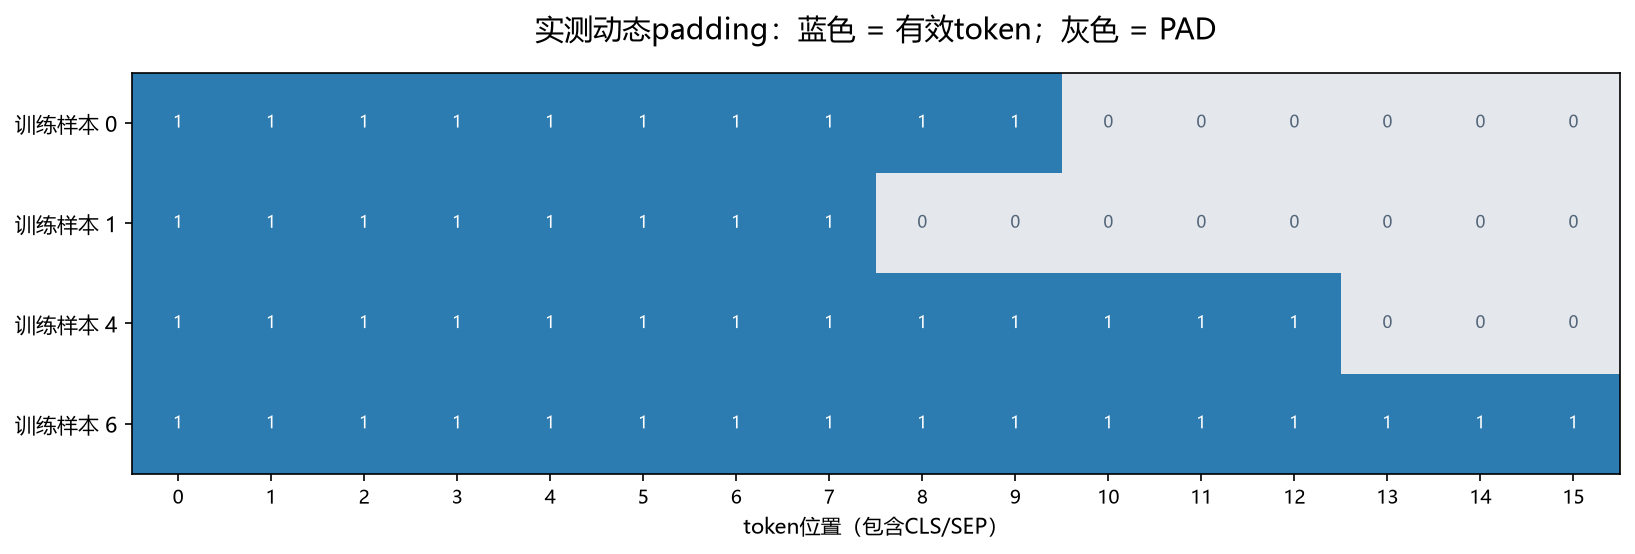

## 24. 交给下一篇的接口：本篇只检查前向，不训练

完成数据准备后，确认IDs/mask形状一致，labels为 `(B,)` 的long整数，输入长度在模型上限内。文本分类模型可接收labels并计算loss，但本篇不反向传播、不更新参数，也不报告准确率。

```python
handoff_batch = collate_reviews([review_data['train'][i] for i in [0,1,4]])
B,L = handoff_batch['input_ids'].shape
assert handoff_batch['attention_mask'].shape == (B,L)
assert handoff_batch['labels'].shape == (B,) and handoff_batch['labels'].dtype == torch.long
assert int(handoff_batch['input_ids'].max()) < classifier.config.vocab_size
assert L <= classifier.config.max_position_embeddings
assert set(handoff_batch['labels'].tolist()) <= {0,1}
with torch.inference_mode():
    handoff_output = classifier(**handoff_batch)
assert handoff_output.logits.shape == (B,2) and torch.isfinite(handoff_output.loss)
print('交接batch:', B, '条 ×', L, 'tokens')
print('模型logits:', tuple(handoff_output.logits.shape))
print('随机模型前向loss:', round(handoff_output.loss.item(),4))
print('本篇参数更新次数:', 0)
```

本段实测输出：

```text
交接batch: 3 条 × 13 tokens
模型logits: (3, 2)
随机模型前向loss: 0.6906
本篇参数更新次数: 0
```

这个loss只验证“标签能进入模型、损失可计算”，不代表训练改善。下一篇再讨论预训练编码器、分类头、冻结或微调、优化器、训练/验证循环与评估。

后续使用 `CrossEntropyLoss`时应传**raw logits**，不要先softmax；现代PyTorch优化器可用 `torch.optim.AdamW`，不要照搬旧版 `from transformers import AdamW`。冻结参数用 `requires_grad=False`，eval模式与no_grad/inference_mode不能互相替代。

## 25. 课件写法的更正与现代接口对照

| 课件或易错写法 | 本篇说明与修正 |
| --- | --- |
| 将pooler描述为平均池化 | BERT是CLS→Linear→tanh；内容均值要另算 |
| 两元素text列表被理解成两条样本 | 用 `tokenizer([A,B])`明确batch；`tokenizer(A,B)`明确句对 |
| `pad_to_max_length=True` | 用 `padding='max_length'`或动态 `padding=True` |
| MLM直接取固定 `logits[0][6]` | 动态定位mask_token_id，支持多个样本与mask |
| QA start/end各自argmax | 限制context、顺序与最大跨度，结合offset还原 |
| 去掉标点再直接返回原文位置 | 保持原文或建立清洗坐标映射 |
| NER直接把token字符串拼起来 | 排除special/PAD，用BIO与原文offset合并 |
| `model(inputs)` | 以字典展开 `model(**inputs)`；额外字段需先处理 |
| 生成时只传input_ids | 批量padding时同时传attention_mask；匹配架构接受的键 |
| 基础BERT + 新分类头直接当成熟分类器 | 新头需要训练与验证；警告应被理解 |
| validation/test跟随train使用drop_last | 保留评估全部样本，通常shuffle=False、drop_last=False |
| 旧Transformers AdamW导入 | 后续训练采用torch.optim.AdamW，核对版本 |

这些说明基于已阅读的PDF，不推断视频或原代码是否另有更新。本篇没有把原课件的示例预测移植为自己的实测结果，也没有把人工CSV数量写成课程原数据数量。

## 26. 复习题与参考答案

1. **AutoModelForSequenceClassification输出什么？** 单标签分类常为 `(B,C)` logits，标签含义从config读取；基础AutoModel通常输出token隐藏表示。
2. **BERT pooler是平均池化吗？** 不是，是CLS位置表示经过Linear与tanh。内容均值要单独排除PAD和特殊token后计算。
3. **两句话批次和句对区别？** 批次是两条样本、B=2；句对是两段组成一条样本、B=1，BERT还用分段ID区分。
4. **一个mask一定等于一个中文词吗？** 不是，一个mask对应一个token，词可能跨多个token。
5. **QA能分别取两个全局最大值吗？** 可能非法，应限制context、s≤e和答案长度，再映射原文offset。
6. **QA输出end包含那个字符吗？** 常见字符offset是排他的end，使用 `context[start:end]`。
7. **生成的最大长度能当作输入上限吗？** 不能，输入tokenizer截断与输出max_new_tokens是两个不同预算。
8. **NER的word一定是无空格的原文吗？** 不保证，可有分词痕迹；原文展示用offset切片。
9. **本篇PER/LOC能等同CLUENER全部标签吗？** 不能，标签体系由数据与checkpoint定义，本例只演示两种实体类型。
10. **CSV能split(',')吗？** 不能，字段内逗号与引号需要CSV解析器。
11. **为什么labels是long型(B,)？** 二分类交叉熵使用每条样本的整数类别ID；不能误变为 `(B,1)` 或浮点概率。
12. **DataCollatorWithPadding负责什么？** 把已编码的不等长列表动态补齐并转成张量；它不替代原始文本分词。
13. **测试集最后一批不足batch_size怎么办？** 本例保留，否则会遗漏样本并可能扭曲评估。
14. **随机小模型loss约0.69说明什么？** 只说明二分类前向损失可计算，不能说明学会了分类。
15. **eval、冻结参数和关闭梯度是同一回事吗？** 不是，分别控制模块行为、参数是否可训练与梯度记录。

练习：把人工CSV换为自有中文评论数据，保持三划分独立，记录标签分布、空文本、重复、token长度与截断率；同时实现在线collate与map+collator，确认同一批文本和标签一致。然后选择匹配中文和任务的checkpoint，完整训练与评估放到第12篇。

## 27. day11资料索引与验证记录

来源：[NLP自然语言处理网盘资料](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码 `1234`。课程目录 `2026最新版NLP自然语言处理`，视频 `03-视频/day11`，共12个文件。

阅读课件：`10-迁移学习-中.pdf` 第35—62页，覆盖后三种Pipeline、六种Auto、具体BERT和输入字典；`11-迁移学习-下.pdf` 第1—11页覆盖中文分类数据加载与预处理。下篇第12—17页仅确认模型网络及训练是后续内容，不在本篇展开。

| 视频 | 原文件主题 | 对应笔记 |
| --- | --- | --- |
| 01 | pipeline方式_阅读理解任务(理解) | 第6、9节 |
| 02 | pipeline方式_文本摘要任务(理解) | 第7、9节 |
| 03 | pipeline方式_NER任务(理解) | 第8、9节 |
| 04 | 自动模型方式_文本分类任务(掌握) | 第4—5、10节 |
| 05 | 自动模型方式_特征提取任务(掌握) | 第11节 |
| 06 | 自动模型方式_完形填空任务(掌握) | 第12节 |
| 07 | 自动模型方式_阅读理解任务(掌握) | 第13—14节 |
| 08 | 自动模型方式_文本摘要任务(理解) | 第15节 |
| 09 | 自动模型方式_NER任务(理解) | 第16节 |
| 10 | 具体模型方式_完形填空任务(掌握) | 第17节 |
| 11 | 迁移学习_中文分类案例_数据加载(掌握) | 第18—20节 |
| 12 | 迁移学习_中文分类案例_数据预处理(掌握) | 第21—24节 |

实测完成：本地六种随机任务模型保存与重载；单句/批次/句对及动态/固定padding；分类logits与概率；QA、摘要、NER Pipeline；BERT pooler公式和内容均值；动态mask定位；问答context约束与人工正确span；摘要generate与Pipeline一致性；人工BIO合并与异常序列拒绝；Auto与具体BERT同权重一致；CSV引号逗号往返；DatasetDict三划分加载；标签与重复质检；DataLoader不丢测试尾批；map+collator与在线collate一致；长度/PAD检查；分类标签前向loss接口。

未执行：公开大模型下载与真实推理、原课程评论数据读取、完整分类训练、真实任务准确率/F1/ROUGE等评估、完整长文多窗口QA。随机模型与人工规则实验不构成这些任务的质量证据。

六张图均为本篇独立绘制、内嵌：任务头、批次与句对、QA坐标、BIO对齐、数据流水线、实测padding mask。代码均在独立临时环境的CPU上执行，不改用户已有项目依赖。

接口参考：[Transformers Pipeline](https://huggingface.co/docs/transformers/main_classes/pipelines)、[Auto类](https://huggingface.co/docs/transformers/model_doc/auto)、[BERT模型](https://huggingface.co/docs/transformers/model_doc/bert)、[Datasets CSV加载](https://huggingface.co/docs/datasets/loading)、[Data collator](https://huggingface.co/docs/transformers/main_classes/data_collator)。本篇记录固定实测版本，网页文档随版本变化需再次核对。